In [1]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
# standardize the data
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# visualizations
import matplotlib.pyplot as plt
import seaborn as sns

# metrics
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.metrics import f1_score

# data loader
from torch.utils.data import DataLoader, Dataset

device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')

In [2]:
# Define the model
class FeedForward(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super(FeedForward, self).__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.relu1 = nn.ReLU()
        self.dropout1 = nn.Dropout(0.5)
        # 
        self.fc2 = nn.Linear(hidden_dim, 32)
        self.relu2 = nn.ReLU()
        self.dropout2 = nn.Dropout(0.3)

        self.fc3 = nn.Linear(32, output_dim)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        out = self.fc1(x)
        out = self.relu1(out)
        out = self.dropout1(out)
        out = self.fc2(out)
        out = self.relu2(out)
        out = self.dropout2(out)
        out = self.fc3(out)
        out = self.sigmoid(out)
        return out

# early stopping
class EarlyStopping:
    def __init__(self, patience=10, verbose=False, delta=0):
        """
        :param patience: How long to wait after last time validation loss improved.
        :param verbose: If True, prints a message for each validation loss improvement.
        :param delta: Minimum change in the monitored quantity to qualify as an improvement.
        """
        self.patience = patience
        self.verbose = verbose
        self.counter = 0 # counter for the number of epochs with no improvement
        self.best_score = None # the best score so far
        self.early_stop = False # whether to stop the training
        self.val_loss_min = np.Inf # the minimum validation loss
        self.delta = delta

    def __call__(self, val_loss, model):
        score = -val_loss # the score is the negative of the validation loss

        if self.best_score is None:
            self.best_score = score
            self.save_checkpoint(val_loss, model)
        elif score < self.best_score + self.delta:
            self.counter += 1
            if self.verbose:
                print(f'EarlyStopping counter: {self.counter} out of {self.patience}')
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_score = score
            self.save_checkpoint(val_loss, model)
            self.counter = 0

    def save_checkpoint(self, val_loss, model):
        if self.verbose:
            print(f'Validation loss decreased ({self.val_loss_min:.6f} --> {val_loss:.6f}). Saving model...')
        torch.save(model.state_dict(), 'checkpoint.pt')
        self.val_loss_min = val_loss


def validate(val_model, val_x, val_y, val_criterion):
    val_x = val_x.to(device)
    val_y = val_y.to(device)
    
    val_model.eval()
    val_total_loss = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        val_outputs = val_model(val_x)
        val_loss = val_criterion(val_outputs, val_y)
        val_total_loss += val_loss.item()

        val_predicted = val_outputs.round()
        val_correct += val_predicted.eq(val_y).sum().item()
        val_total += val_y.size(0)

        val_epoch_loss = val_total_loss / val_total
        val_epoch_acc = val_correct / val_total
        val_epoch_f1 = f1_score(val_y.cpu().numpy(), val_predicted.cpu().numpy())

    return val_epoch_loss, val_epoch_acc, val_epoch_f1

def prepare_data(combined, train_data_path, test_data_path = '', test_size=0.2, frequencies=None):
    if frequencies and combined:
        df = pd.read_csv(train_data_path)
        df, val = remove_frequencies(df, frequencies)
        y = df['machine_state']
        X_train, X_test, y_train, y_test = train_test_split(df, y, test_size=test_size, random_state=42)
        val_y = val['machine_state']
        X_train = X_train.drop('Unnamed: 0', axis=1)
        X_test = X_test.drop('Unnamed: 0', axis=1)
        val = val.drop('Unnamed: 0', axis=1)
        return X_train, y_train, X_test, y_test, val, val_y
    elif frequencies:
        df_train = pd.read_csv(train_data_path)
        df_test = pd.read_csv(test_data_path)
        df_train, validation = remove_frequencies(df_train, frequencies)
        df_test, _ = remove_frequencies(df_test, frequencies)
        X_train = df_train.drop('machine_state', axis=1)
        y_train = df_train['machine_state']
        X_test = df_test.drop('machine_state', axis=1)
        y_test = df_test['machine_state']
        val = validation.drop('machine_state', axis=1)
        val_y = validation['machine_state']
        X_train = X_train.drop('Unnamed: 0', axis=1)
        X_test = X_test.drop('Unnamed: 0', axis=1)
        val = val.drop('Unnamed: 0', axis=1)
        return X_train, y_train, X_test, y_test, val, val_y
    elif combined:
        df = pd.read_csv(train_data_path)
        y = df['machine_state']
        df = df.drop('machine_state', axis=1)
        X_train, X_test, y_train, y_test = train_test_split(df, y, test_size=test_size, random_state=42)
        X_train = X_train.drop('Unnamed: 0', axis=1)
        X_test = X_test.drop('Unnamed: 0', axis=1)
        return X_train, y_train, X_test, y_test
    else:
        df_train = pd.read_csv(train_data_path)
        df_test = pd.read_csv(test_data_path)
        X_train = df_train.drop('machine_state', axis=1)
        y_train = df_train['machine_state']
        X_test = df_test.drop('machine_state', axis=1)
        y_test = df_test['machine_state']
        X_train = X_train.drop('Unnamed: 0', axis=1)
        X_test = X_test.drop('Unnamed: 0', axis=1)
        return X_train, y_train, X_test, y_test

def remove_frequencies(d, frequencies):
    removed = d[~d['Frequency L2 Current'].isin(frequencies)]
    rest = d[d['Frequency L2 Current'].isin(frequencies)]
    return rest, removed

def train(X_train, y_train, X_test, y_test, show_results=True):
    X_train = X_train.to_numpy()
    y_train = y_train.to_numpy()
    X_test = X_test.to_numpy()
    y_test = y_test.to_numpy()
    
    
    X_train = torch.FloatTensor(X_train)
    y_train = torch.FloatTensor(y_train)
    X_test = torch.FloatTensor(X_test)
    y_test = torch.FloatTensor(y_test)

    y_train = y_train.unsqueeze(1)
    y_test = y_test.unsqueeze(1)

    train_dataset = torch.utils.data.TensorDataset(X_train, y_train)
    train_loader = DataLoader(train_dataset, batch_size=512, shuffle=True)

    input_dimensions = X_train.shape[1]
    hidden_dimensions = 32
    output_dimensions = 1
    model = FeedForward(input_dimensions, hidden_dimensions, output_dimensions)
    model.to(device)

    criterion = nn.BCELoss()
    optim = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=0.1)
    # optim = torch.optim.SGD(model.parameters(), lr=0.001, momentum=0.9, weight_decay=0.1)
    early_stopping = EarlyStopping(patience=10, verbose=True)
    
    losses, accuracies, f1_scores = epochs(100, model, train_loader, X_test, y_test, criterion, optim, early_stopping)
    
    training_results(losses, accuracies, f1_scores)

    if show_results:
        eval_model(model, X_test, y_test)

    return model

def epochs(epochs, model, train_loader, X_test, y_test, criterion, optim, early_stopping):
    # storing metrics
    losses = []
    accuracies = []
    f1_scores = []

    for epoch in range(epochs):
        total_loss = 0
        correct = 0
        total = 0
        
        for data, target in train_loader:
            data, target = data.to(device), target.to(device)
            outputs = model(data)
            loss = criterion(outputs, target)
            total_loss += loss.item()

            # accuracy
            # predicted = outputs.round()
            # correct += predicted.eq(target).sum().item()
            total += target.size(0)

            # backpropagation
            optim.zero_grad()
            loss.backward()
            optim.step()
        
        # validation
        epoch_loss, epoch_acc, epoch_f1 = validate(model, X_test, y_test, criterion)
        print(f'Epoch: {epoch+1}, Loss: {epoch_loss}, Accuracy: {epoch_acc}, F1 Score: {epoch_f1}')

        # Append metrics to the lists
        losses.append(epoch_loss)
        accuracies.append(epoch_acc)
        f1_scores.append(epoch_f1)
        
        # early stopping
        early_stopping(epoch_loss, model)
        if early_stopping.early_stop:
            print('Early stopping has been triggered.')
            break
            
    return losses, accuracies, f1_scores

def training_results(losses, accuracies, f1_scores):
    # Plot the metrics
    plt.figure(figsize=(12, 4))
    
    plt.subplot(1, 3, 1)
    plt.plot(losses, label='Loss')
    plt.legend()
    
    plt.subplot(1, 3, 2)
    plt.plot(accuracies, label='Accuracy')
    plt.legend()
    
    plt.subplot(1, 3, 3)
    plt.plot(f1_scores, label='F1 Score')
    plt.legend()
    
    plt.show()

def eval_model(model, X_val, y_val):
    # predict the validation data
    scaler = StandardScaler()
    X_val = scaler.fit_transform(X_val)
    #
    
    X_val = torch.FloatTensor(X_val)
    y_val = torch.FloatTensor(y_val)
    X_val = X_val.to(device)
    y_val = y_val.to(device)
    
    model.eval()
    with torch.no_grad():
        y_pred = model(X_val)
        y_pred = y_pred.round()

    # calculate the accuracy
    y_val = y_val.cpu().numpy()
    y_pred = y_pred.cpu().numpy()
    accuracy = accuracy_score(y_val, y_pred)
    cm = confusion_matrix(y_val, y_pred)
    report = classification_report(y_val, y_pred)

    # print classification report
    print(report)
    print(f'Accuracy: {accuracy}')

    # plot confusion matrix
    plt.figure(figsize=(5, 2))
    sns.heatmap(cm, annot=True, fmt='d')
    plt.xlabel('Predicted')
    plt.ylabel('Truth')
    plt.show()

In [3]:
# Load the data complete 
# X_train, y_train, X_test, y_test = prepare_data(True, '../datasets/complete.csv')
# model = train(X_train, y_train, X_test, y_test, show_results=True)


Epoch: 1, Loss: 0.0013664965843408375, Accuracy: 0.7580481192815994, F1 Score: 0.0
Validation loss decreased (inf --> 0.001366). Saving model...
Epoch: 2, Loss: 0.0013664965843408375, Accuracy: 0.7580481192815994, F1 Score: 0.0
Validation loss decreased (0.001366 --> 0.001366). Saving model...
Epoch: 3, Loss: 0.0013664965843408375, Accuracy: 0.7580481192815994, F1 Score: 0.0
Validation loss decreased (0.001366 --> 0.001366). Saving model...
Epoch: 4, Loss: 0.0013664965843408375, Accuracy: 0.7580481192815994, F1 Score: 0.0
Validation loss decreased (0.001366 --> 0.001366). Saving model...
Epoch: 5, Loss: 0.0013664965843408375, Accuracy: 0.7580481192815994, F1 Score: 0.0
Validation loss decreased (0.001366 --> 0.001366). Saving model...
Epoch: 6, Loss: 0.0013664965843408375, Accuracy: 0.7580481192815994, F1 Score: 0.0
Validation loss decreased (0.001366 --> 0.001366). Saving model...
Epoch: 7, Loss: 0.0013664965843408375, Accuracy: 0.7580481192815994, F1 Score: 0.0
Validation loss decrea

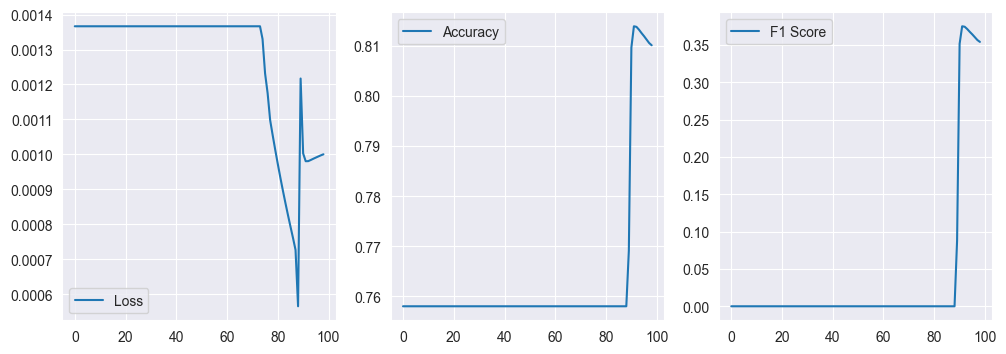

              precision    recall  f1-score   support

         0.0       0.87      0.61      0.72     13422
         1.0       0.37      0.70      0.48      4284

    accuracy                           0.64     17706
   macro avg       0.62      0.66      0.60     17706
weighted avg       0.75      0.64      0.66     17706

Accuracy: 0.6356037501411951


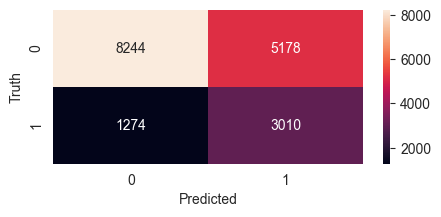

In [4]:
# Load the data train and test
X_train, y_train, X_test, y_test = prepare_data(False, '../datasets/train_data.csv', '../datasets/test_data.csv')
model = train(X_train, y_train, X_test, y_test, show_results=True)

In [5]:
# # Load the best model
model.load_state_dict(torch.load('checkpoint.pt'))

# Evaluate the model
model.eval()
criterion = nn.BCELoss()
with torch.no_grad():
    outputs = model(X_test)
    loss = criterion(outputs, y_test)
    predicted = outputs.round()
    correct = predicted.eq(y_test).sum().item()
    total = y_test.size(0)
    accuracy = correct / total
    f1 = f1_score(y_test.cpu().numpy(), predicted.cpu().numpy())
    print(f'Loss: {loss.item()}, Accuracy: {accuracy}, F1 Score: {f1}')

TypeError: linear(): argument 'input' (position 1) must be Tensor, not DataFrame

In [ ]:
# Save the model
# torch.save(model.state_dict(), 'feedforward_model.pt')



In [ ]:
# Load the model

In [ ]:
# predicted = predicted.cpu().numpy()


In [ ]:
# # add the predicted values to the test data
# test_df['predicted'] = predicted


In [ ]:
# test_df[['Frequency L2 Current', 'machine_state', 'predicted']]

In [ ]:
# for every frequency, get the number of equal values between machine state and predicted
# test_df.groupby('Frequency L2 Current').apply(lambda x: (x['machine_state'] == x['predicted']).sum(), include_groups=False)

In [ ]:
# for each frequency, get the number of times the machine was in a state where machine state and predicted are different
# test_df.groupby('Frequency L2 Current').apply(lambda x: (x['machine_state'] != x['predicted']).sum(), include_groups=False)


In [ ]:
# create a new frequency column if Frequency L2 Current is greater than 25 high, lower than 25 and higher 
